# Phase 6: Exploratory analysis and maps (SQ1)

In this notebook we look at how car ownership, distance to the nearest station and train disruptions are spread across Dutch neighbourhoods in 2023. This answers SQ1. We use maps (GeoPandas, as in the lecture) and simple charts.

## Step 1: We import the libraries and set the folder where the cleaned data is stored

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

PROCESSED = Path('data/cleaned_data')

## Step 2: We load the master table (Phase 5), the neighbourhood shapes and the stations

In [2]:
# Load the master table (Phase 5)
master = pd.read_pickle(PROCESSED / 'master.pkl')

# Load the neighbourhood map 
neighbourhood_map = gpd.read_file(PROCESSED / 'buurten_kaart.gpkg')

# Load the stations
stations = pd.read_pickle(PROCESSED / 'stations.pkl')

c:\Users\alecm\anaconda3\envs\TIL6022-26\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


## Step 3: Summary statistics


In [3]:
# Show a summary (count, average, smallest and largest value, etc.) of the main columns in the master table (one row = one neighbourhood)
# autos_per_hh: number of cars per household in the neighbourhood (2023)
# afstand_station: distance from the neighbourhood to the nearest station (in km)
# storingen_per_jaar: average number of disruptions per year at the nearest station (2021–2023)
# minuten_per_jaar: average number of disruption minutes per year at the nearest station (2021–2023)
master[['autos_per_hh', 'afstand_station', 'storingen_per_jaar', 'minuten_per_jaar']].describe().round(2)

,autos_per_hh,afstand_station,storingen_per_jaar,minuten_per_jaar
count,9039.00,9039.00,9039.00,9039.00
mean,1.12,3.80,69.95,14317.69
std,0.36,2.48,64.84,14543.17
min,0.00,0.10,2.00,355.67
25%,0.90,1.70,30.33,4755.00
50%,1.10,3.10,47.67,10458.33
75%,1.40,5.60,91.33,16496.33
max,2.50,10.00,535.33,100046.33


## Step 4: Put the data on the map
The master table has no shapes, and the map has no numbers. We join them using the neighbourhood code, so every shape gets its numbers.

In [4]:
# Add the numbers from the master table to the shapes on the map 
# on='buurtcode' means that the merge is done based on the 'buurtcode' column, the code that is different for every neighbourhood
neighbourhoods = neighbourhood_map.merge(master, on='buurtcode')

# Check: how many neighbourhoods are on the map, and how many have our data
print('Neighbourhoods on the map:   ', len(neighbourhood_map))
print('Neighbourhoods with our data:', len(neighbourhoods))

Neighbourhoods on the map:    14515
Neighbourhoods with our data: 9039


## Step 5: Map of car ownership per neighbourhood (2023)
Each neighbourhood is coloured by the number of cars per household. Neighbourhoods that are not in our sample (for example business zones or areas without data) are shown in light grey.

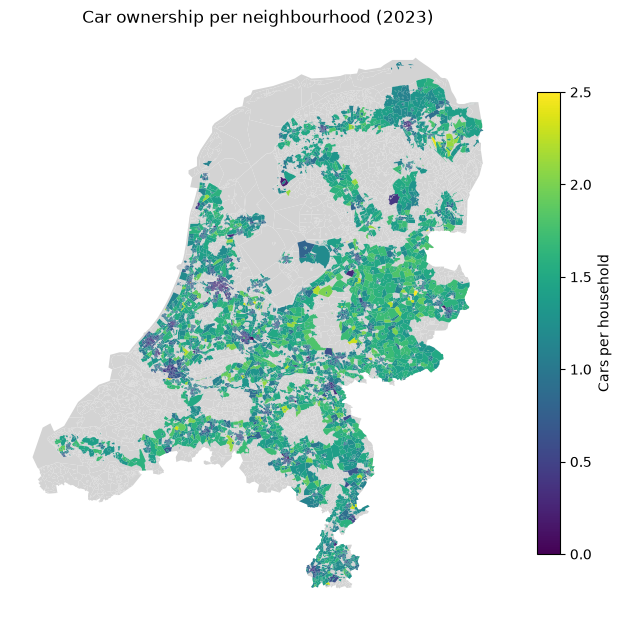

In [5]:
# Draw all neighbourhoods in light grey as a background
ax = neighbourhood_map.plot(color='lightgrey', figsize=(8, 10))

# Draw our neighbourhoods on top, coloured by car ownership
# autos_per_hh: number of cars per household in the neighbourhood (2023)
#cmap='viridis' is a colour map that goes from dark purple (low values) to yellow (high values)
#legend=True means that a legend will be added to the map
#legend_kwds={'label': 'Cars per household', 'shrink': 0.6} means that the legend will have a label and will be shrunk to 60% of its original size
neighbourhoods.plot(ax=ax, column='autos_per_hh', cmap='viridis', legend=True,
           legend_kwds={'label': 'Cars per household', 'shrink': 0.6})

# Add a title and hide the coordinates around the map
ax.set_title('Car ownership per neighbourhood (2023)')

# Hide the coordinates around the map
ax.set_axis_off()

#show the map
plt.show()

## Step 6: Stations on top of the map of car ownership per neighbourhood (2023)
We add the railway stations as dots: red for major stations and blue for minor stations. This shows whether car ownership is lower around stations.

Step 6a: turn the station coordinates into points 

In [6]:
# Make a point for every station from its longitude and latitude
# gpd.points_from_xy() takes two arguments: the longitude and latitude columns from the stations dataframe
# stations['geo_lng'] is the longitude column, and stations['geo_lat'] is the latitude column
points = gpd.points_from_xy(stations['geo_lng'], stations['geo_lat'])

# Create a GeoDataFrame from the stations dataframe and the points
#gpd.GeoDataFrame() takes three arguments: the stations dataframe, the points, and the coordinate system (CRS: tells how the coordinates should be read)
# geometry=points means that the points will be used as the geometry for the GeoDataFrame
# The CRS is set to 'EPSG:4326', which is the standard for GPS coordinates (longitude and latitude)
station_points = gpd.GeoDataFrame(stations, geometry=points, crs='EPSG:4326')

# Convert the points to the same coordinate system as the neighbourhood map
station_points = station_points.to_crs(neighbourhood_map.crs)

Step 6b: We split the stations into major and minor stations (same grouping as in Phase 3).

In [7]:
major_types = ['megastation', 'knooppuntIntercitystation', 'intercitystation']

# isin gives True for major stations; the ~ turns True into False and the other way around
major_stations = station_points[station_points['type'].isin(major_types)]
minor_stations = station_points[~station_points['type'].isin(major_types)]

Step 6c: we map the neighbourhoods in grey tones, and the stations on top. The major stations are shown in red, and the minor stations in blue

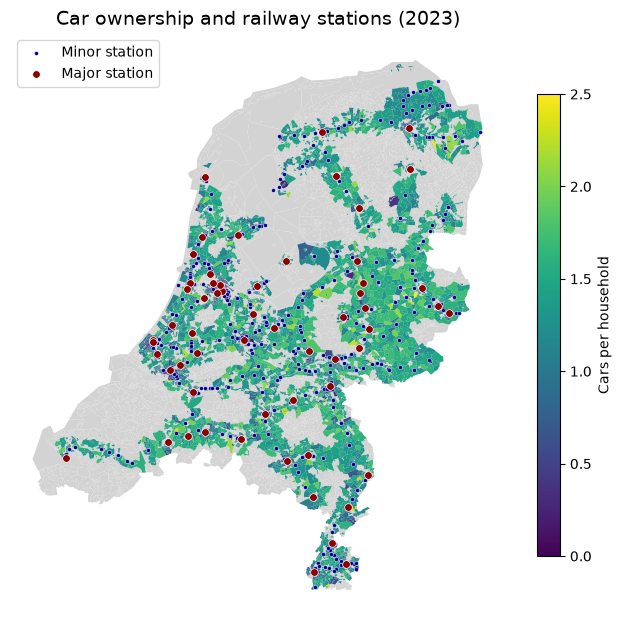

In [8]:
# Background: all neighbourhoods in very light grey
ax = neighbourhood_map.plot(color='lightgrey', edgecolor='none', figsize=(8, 10))

# Car ownership in the neighbourhoods with our data, coloured by number of cars per household
neighbourhoods.plot(ax=ax, column='autos_per_hh', cmap='viridis', edgecolor='none',
                    legend=True, legend_kwds={'label': 'Cars per household', 'shrink': 0.6})

# Stations on top; the thin white edge makes the dots visible on dark areas too
# ax=ax means that the stations will be drawn on the same map as the neighbourhoods
# color='Darkblue' means that the minor stations will be drawn in dark blue
# markersize=8 means that the minor stations will be drawn with a size of 8
# edgecolor='white' means that the minor stations will have a white edge
# linewidth=0.3 means that the edge of the minor stations will be drawn with a width of 0.3
# label='Minor station' means that the minor stations will be labelled as 'Minor station' in the legend
minor_stations.plot(ax=ax, color='Darkblue', markersize=8, edgecolor='white',
                    linewidth=0.3, label='Minor station')
# same has been done for the major stations, but with a larger size and a different colour
major_stations.plot(ax=ax, color='Darkred', markersize=30, edgecolor='white',
                    linewidth=0.5, label='Major station')

# Add a title, a legend and hide the coordinates around the map
ax.set_title('Car ownership and railway stations (2023)', fontsize=14)
ax.legend(loc='upper left')
ax.set_axis_off()

#show the map
plt.show()

In [9]:
# Average car ownership near a major station and near a minor station
# station_groot is True for a major station and False for a minor station
near_major = master[master['station_groot'] == True]
near_minor = master[master['station_groot'] == False]

print('Near a major station:', round(near_major['autos_per_hh'].mean(), 2), 'cars per household')
print('Near a minor station:', round(near_minor['autos_per_hh'].mean(), 2), 'cars per household')

Near a major station: 0.94 cars per household
Near a minor station: 1.18 cars per household


## Step 7: Car ownership by distance to the station
We put the neighbourhoods in groups by distance to the nearest station and calculate the average car ownership per group. This is easier to read than a scatter plot with 11,000 dots.

Step 7a: We make the distance groups and calculate the average car ownership and the number of neighbourhoods per group.

In [10]:
# group_borders defines the distance groups in km
group_borders = [0, 1, 2, 3, 5, 10, 20, 60]

# group_names defines the names of the distance groups
group_names = ['0-1', '1-2', '2-3', '3-5', '5-10', '10-20', '20+']

# pd.cut() puts every neighbourhood in one of the distance groups, based on its distance to the station
# master['afstand_station'] is the distance from the neighbourhood to the nearest station (in km)
# bins=group_borders means that the distance groups will be defined by the group_borders list
# labels=group_names means that the distance groups will be labelled by the group_names list
master['distance_group'] = pd.cut(master['afstand_station'], bins=group_borders, labels=group_names)

# master.groupby() is used to group the data by distance group
# observed=True means that only the groups that are present in the data will be included in the result
# ['autos_per_hh'] means that only the autos_per_hh column will be used for the calculation
# mean() calculates the average number of cars per household for each distance group
average_cars = master.groupby('distance_group', observed=True)['autos_per_hh'].mean()

# master.groupby() is used to group the data by distance group
# observed=True means that only the groups that are present in the data will be included in the result
# ['autos_per_hh'] means that only the autos_per_hh column will be used for the calculation
# count() counts the number of neighbourhoods in each distance group
number_of_neighbourhoods = master.groupby('distance_group', observed=True)['autos_per_hh'].count()

# show both results in one table
# average_cars.round(2) rounds the average number of cars per household to 2 decimal places
pd.DataFrame({
    'avg cars per household': average_cars.round(2),
    'neighbourhoods': number_of_neighbourhoods,
})

,avg cars per household,neighbourhoods
distance_group,,
0-1,0.93,848
1-2,0.94,1978
2-3,1.03,1604
3-5,1.19,1935
5-10,1.31,2674


Step 7b: We show the average car ownership per distance group in a bar chart, with the exact value above each bar

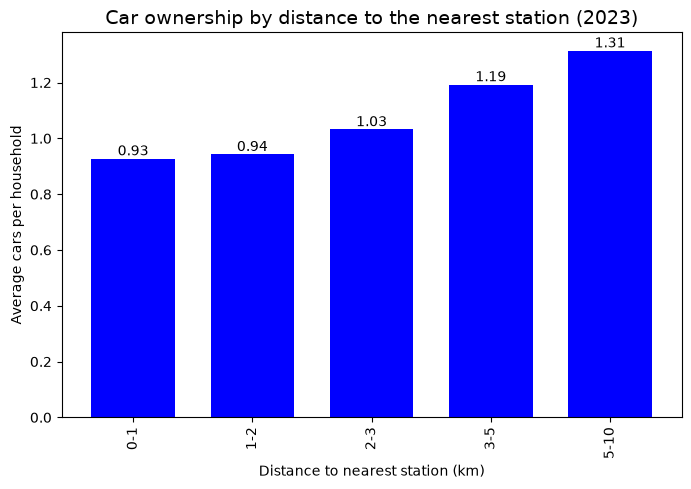

In [11]:
# Draw one bar per distance group
# kind='bar' means that a bar chart will be drawn
# color='Blue' means that the bars will be drawn in blue
# width=0.7 means that the bars will have a width of 0.7
# figsize=(8, 5) means that the figure will have a width of 8 and a height of 5
ax = average_cars.plot(kind='bar', color='Blue', width=0.7, figsize=(8, 5))

# Write the average above each bar
# ax.bar_label() is used to add labels to the bars in the bar chart
# ax.containers[0] are the bars we just drew
# fmt='%.2f' means that the labels will be formatted to 2 decimal places
ax.bar_label(ax.containers[0], fmt='%.2f')

# Add labels and a title

# ax.set_xlabel() sets the label for the x-axis
ax.set_xlabel('Distance to nearest station (km)')

# ax.set_ylabel() sets the label for the y-axis
ax.set_ylabel('Average cars per household')

# ax.set_title() sets the title of the bar chart
ax.set_title('Car ownership by distance to the nearest station (2023)', fontsize=14)

# show the bar chart
plt.show()

## Step 8: Train disruptions per station
Each station is shown as a dot. The colour shows the average number of disruptions per year (2021–2023).

Step 8a: Merge station points with disruption data

In [12]:
# Add the number of disruptions to each station (from the master table)
# master[['station_code', 'storingen_per_jaar']] selects the station code and the average number of disruptions per year from the master table
# drop_duplicates() is used to remove duplicate rows from the master table, so that each station is only represented once
disruptions = master[['station_code', 'storingen_per_jaar']].drop_duplicates()

#station_points.merge() is used to merge the station_points GeoDataFrame with the disruptions DataFrame
# left_on='code' means that the merge will be done based on the 'code' column in the station_points GeoDataFrame
# right_on='station_code' means that the merge will be done based on the 'station_code' column in the disruptions DataFrame
# how='left' means that all rows from the station_points GeoDataFrame will be included in the result
station_points = station_points.merge(disruptions, left_on='code', right_on='station_code', how='left')

# Stations that are not the nearest station of any neighbourhood have no value; we leave them out
# notna() is used to check for missing values in the 'storingen_per_jaar' column
station_points = station_points[station_points['storingen_per_jaar'].notna()]

Step 8b: create map of average number of disruptions per year at the nearest station (2021–2023)

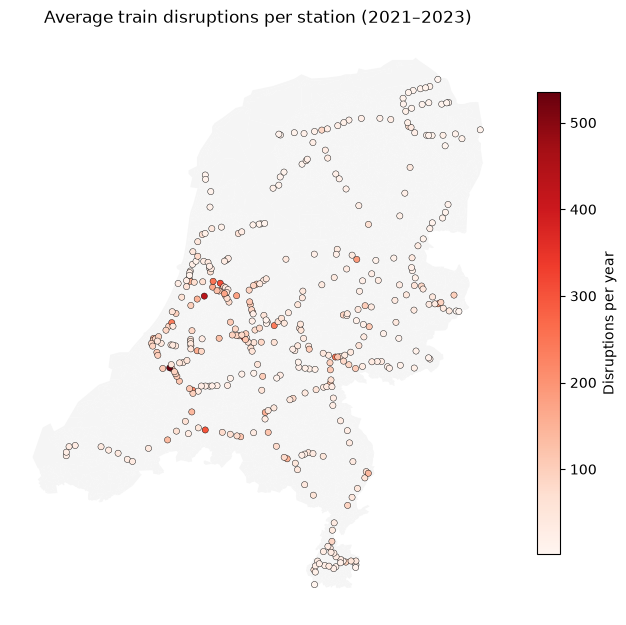

In [13]:
# neighbourhood_map.plot() is used to draw the neighbourhoods on the map
# color='whitesmoke' means all neighbourhoods in very light grey
# edgecolor='none' means that the neighbourhoods will not have a border
# figsize=(8, 10) means that the figure will have a width of 8 and a height of 10

ax = neighbourhood_map.plot(color='whitesmoke', edgecolor='none', figsize=(8, 10))

# station_points.plot() is used to draw the stations on the map
# ax=ax means that the stations will be drawn on the same map as the neighbourhoods
# column='storingen_per_jaar' means that the stations will be coloured based on the average number of disruptions per year
# cmap='Reds' means that the stations will be coloured from light red (low values) to dark red (high values)
# markersize=20 means that the stations will be drawn with a size of 20
# edgecolor='black' means that the stations will have a black edge
# linewidth=0.3 means that the edge of the stations will be drawn with a width of 0.3
# legend=True means that a legend will be added to the map
# legend_kwds={'label': 'Disruptions per year', 'shrink': 0.6} means that the legend will have a label and will be shrunk to 60% of its original size
station_points.plot(ax=ax, column='storingen_per_jaar', cmap='Reds', markersize=20, edgecolor='black', linewidth=0.3, legend=True,
                    legend_kwds={'label': 'Disruptions per year', 'shrink': 0.6})

# Add a title and hide the coordinates around the map
ax.set_title('Average train disruptions per station (2021–2023)')
ax.set_axis_off()

#show the map
plt.show()

Step 8c: look at the 10 stations with the most disruptions per year

In [14]:
# The 10 stations with the most disruptions
# station_points.sort_values() is used to sort the stations based on the average number of disruptions per year
# ascending=False means that the stations will be sorted in descending order (from most to least disruptions)
# [['name_long', 'type', 'storingen_per_jaar']] selects the columns to be displayed in the result
# head(10) selects the first 10 rows of the result
station_points.sort_values('storingen_per_jaar', ascending=False)[['name_long', 'type', 'storingen_per_jaar']].head(10)



,name_long,type,storingen_per_jaar
288,Rotterdam Centraal,megastation,535.333333
303,Schiphol Airport,megastation,433.333333
330,Utrecht Centraal,megastation,355.666667
22,Amsterdam Centraal,megastation,311.000000
68,Breda,knooppuntIntercitystation,299.333333
37,Arnhem Centraal,knooppuntIntercitystation,251.666667
28,Amsterdam Sloterdijk,knooppuntIntercitystation,251.000000
17,Amersfoort Centraal,knooppuntIntercitystation,241.000000
226,Leiden Centraal,knooppuntIntercitystation,239.000000
111,Dordrecht,knooppuntIntercitystation,215.666667


## Findings (SQ1)

- Car ownership is lowest in the big cities and highest in rural areas (map in Step 5).
- Average car ownership rises from about 0.9 cars per household within 2 km of a station to about 1.3 beyond 5 km; further away than 5 km it stays about the same (Step 7).
- Neighbourhoods near a major station have fewer cars (about 1.0 per household) than neighbourhoods near a minor station (about 1.2) (Step 6).
- Disruptions are concentrated at the large stations in the Randstad: Rotterdam Centraal, Schiphol Airport, Utrecht Centraal and Amsterdam Centraal have the most disruptions per year (Step 8).